# Importação de Bibliotecas

In [16]:
import pandas as pd
import numpy as np
import seaborn as sns

from ucimlrepo import fetch_ucirepo # Importação de Dados
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, matthews_corrcoef, confusion_matrix, f1_score

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# 1) Preparação dos Dados

In [17]:
# Busca do Dataset
rt_iot2022 = fetch_ucirepo(id=942)

# Seperação das features com a coluna Target
x = rt_iot2022.data.features
y = rt_iot2022.data.targets

In [18]:
# União das Linhas e Colunas
df_rt_iot2022 = pd.concat([x, y], axis=1)
target_column = y.columns[0]

print(f'Shape: {df_rt_iot2022.shape}')
print(f'Target: {target_column}\n')

df_rt_iot2022.head(15)

Shape: (123117, 84)
Target: Attack_type



,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,down_up_ratio,fwd_header_size_tot,fwd_header_size_min,fwd_header_size_max,bwd_header_size_tot,bwd_header_size_min,bwd_header_size_max,flow_FIN_flag_count,flow_SYN_flag_count,flow_RST_flag_count,fwd_PSH_flag_count,bwd_PSH_flag_count,flow_ACK_flag_count,fwd_URG_flag_count,bwd_URG_flag_count,flow_CWR_flag_count,flow_ECE_flag_count,fwd_pkts_payload.min,fwd_pkts_payload.max,fwd_pkts_payload.tot,fwd_pkts_payload.avg,fwd_pkts_payload.std,bwd_pkts_payload.min,bwd_pkts_payload.max,bwd_pkts_payload.tot,bwd_pkts_payload.avg,bwd_pkts_payload.std,flow_pkts_payload.min,flow_pkts_payload.max,flow_pkts_payload.tot,flow_pkts_payload.avg,flow_pkts_payload.std,fwd_iat.min,fwd_iat.max,fwd_iat.tot,fwd_iat.avg,fwd_iat.std,bwd_iat.min,bwd_iat.max,bwd_iat.tot,bwd_iat.avg,bwd_iat.std,flow_iat.min,flow_iat.max,flow_iat.tot,flow_iat.avg,flow_iat.std,payload_bytes_per_second,fwd_subflow_pkts,bwd_subflow_pkts,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_bytes,bwd_bulk_bytes,fwd_bulk_packets,bwd_bulk_packets,fwd_bulk_rate,bwd_bulk_rate,active.min,active.max,active.tot,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,0.156193,0.437341,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,76,8.444444,13.115936,0,23,32,6.4,9.555103,0,33,108,7.714286,11.618477,761.985779,2.972918e+07,3.201160e+07,4001449.734,10403073.63,4438.877106,1511693.954,2.026391e+06,506597.757339,680406.147100,761.985779,2.972918e+07,3.201160e+07,2.462431e+06,8.199747e+06,3.373777,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.282415e+06,2.282415e+06,2.282415e+06,2.282415e+06,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,0.156821,0.439097,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,76,8.444444,13.115936,0,23,32,6.4,9.555103,0,33,108,7.714286,11.618477,247.001648,2.985528e+07,3.188358e+07,3985448.003,10463455.56,4214.048386,1576435.804,1.876261e+06,469065.249000,741351.686200,247.001648,2.985528e+07,3.188358e+07,2.452583e+06,8.242459e+06,3.387323,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.028307e+06,2.028307e+06,2.028307e+06,2.028307e+06,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,0.155647,0.435811,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,74,8.222222,12.852799,0,21,30,6.0,8.689074,0,33,104,7.428571,11.229866,283.956528,2.984215e+07,3.212405e+07,4015506.625,10442377.92,2456.903458,1476048.946,2.013770e+06,503442.466300,660344.360027,283.956528,2.984215e+07,3.212405e+07,2.471081e+06,8.230593e+06,3.237450,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.281904e+06,2.281904e+06,2.281904e+06,2.281904e+06,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,0.156440,0.438033,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,74,8.222222,12.852799,0,21,30,6.0,8.689074,0,33,104,7.428571,11.229866,288.963318,2.991377e+07,3.196106e+07,3995132.893,10482528.22,3933.906555,1551892.042,1.883784e+06,470946.013927,724569.317900,288.963318,2.991377e+07,3.196106e+07,2.458543e+06,8.257786e+06,3.253959,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.047288e+06,2.047288e+06,2.047288e+06,2.047288e+06,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,0.156728,0.438839,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,76,8.444444,13.115936,0,23,32,6.4,9.555103,0,33,108,7.714286,11.618477,387.907028,2.981470e+07,3.190236e+07,3987795.234,10447019.10,3005.027771,1632083.178,1.9359

#### 1.1) Remoção de Colunas e Duplicadas

In [19]:
# Colunas Constantes
constant_columns = [c for c in df_rt_iot2022.columns if df_rt_iot2022[c].nunique() <= 1]

# Colunas Redundantes e Ids
redundant_columns = ['bwd_pkts_payload.max', 'fwd_pkts_payload.min', 'fwd_iat.tot', 'idle.min', 'flow_pkts_per_sec',
                    'bwd_bulk_packets', 'flow_ACK_flag_count', 'active.tot', 'bwd_pkts_tot', 'fwd_bulk_rate', 'fwd_bulk_packets',
                    'idle.avg', 'flow_iat.std', 'flow_iat.max', 'flow_iat.tot', 'bwd_pkts_payload.tot', 'bwd_iat.avg'
                    ]

# Portas de Origem e Destino
id_columns = ['id.resp_p', 'id.orig_p']

df_rt_iot2022 = df_rt_iot2022.drop(columns=redundant_columns + id_columns + constant_columns, axis=1)

# Remoção de Duplicadas
df_rt_iot2022 = df_rt_iot2022.drop_duplicates().reset_index(drop=True)

print(f'Shape: {df_rt_iot2022.shape}')
print(f'Target: {target_column}\n')

Shape: (18283, 64)
Target: Attack_type



# 2) Treinamento do Modelo

#### 2.1) Separação dos Dados

In [20]:
X = df_rt_iot2022.drop(columns=[target_column], axis=1)
y = df_rt_iot2022[target_column]

In [21]:
# Transformação de colunas categóricas para numéricas
x_encoded = pd.get_dummies(data=X, columns=['proto', 'service'], drop_first=True, dtype=int)

# Mapeamento da coluna target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Separação de dados de treino e teste
X_train, X_test, y_train, y_test = train_test_split(x_encoded, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

#### 2.2) Aplicação do Modelo

In [22]:
rf_model = RandomForestClassifier(n_estimators=300, random_state=42, class_weight='balanced_subsample', n_jobs=-1)
rf_model.fit(X_train, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [23]:
y_test_pred = rf_model.predict(X_test)

In [24]:
print(f"Acurácia: {accuracy_score(y_true=y_test, y_pred=y_test_pred)}")
print(f"Acurácia Balanceada: {balanced_accuracy_score(y_true=y_test, y_pred=y_test_pred)}")

print(f"Macro F1-Score: {f1_score(y_true=y_test, y_pred=y_test_pred, average='macro')}")
print(f"Weighted F1-Score: {f1_score(y_true=y_test, y_pred=y_test_pred, average='weighted')}\n")

print('Relatório de Classificação')
print(classification_report(y_test, y_test_pred, zero_division=0, target_names=le.classes_))

Acurácia: 0.9857806945583811
Acurácia Balanceada: 0.8315198537797471
Macro F1-Score: 0.8474854767495538
Weighted F1-Score: 0.9854610151820474

Relatório de Classificação
                            precision    recall  f1-score   support

            ARP_poisioning       0.98      0.99      0.99      1060
            DDOS_Slowloris       0.89      0.93      0.91       107
             DOS_SYN_Hping       1.00      1.00      1.00        11
              MQTT_Publish       1.00      1.00      1.00       828
Metasploit_Brute_Force_SSH       0.83      0.71      0.77         7
             NMAP_FIN_SCAN       0.00      0.00      0.00         1
         NMAP_OS_DETECTION       1.00      1.00      1.00        15
             NMAP_TCP_scan       1.00      1.00      1.00         9
             NMAP_UDP_SCAN       0.73      0.56      0.64        39
       NMAP_XMAS_TREE_SCAN       1.00      0.81      0.90        16
               Thing_Speak       0.99      0.99      0.99      1520
             

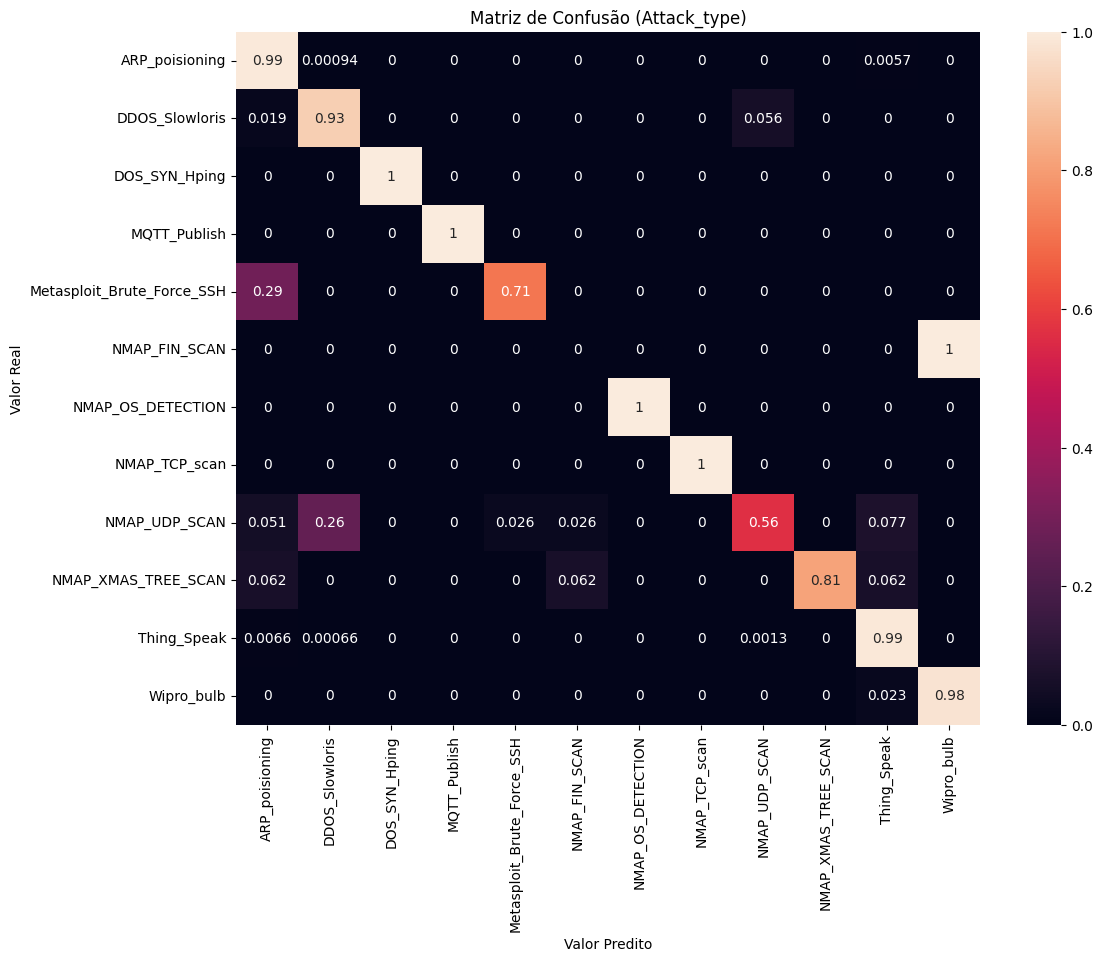

In [25]:
cm = confusion_matrix(y_true=y_test, y_pred=y_test_pred, normalize="true")

fig, axes = plt.subplots(figsize=(12, 9))
sns.heatmap(
    cm, annot=True, ax=axes,
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title(f"Matriz de Confusão ({target_column})")
axes.set_xlabel("Valor Predito")
axes.set_ylabel("Valor Real")
plt.show()

#### 2.3) Avaliação de Importâncias

In [26]:
df_importances = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

print("Colunas por Grau de Importância")
print(df_importances, "\n")

print(f'Soma das 10 colunas mais importantes: {df_importances.head(10).sum()}')
print(f'Soma das 30 colunas menos importantes: {df_importances.tail(30).sum()}')

Colunas por Grau de Importância
fwd_pkts_payload.max        0.040110
fwd_URG_flag_count          0.039610
flow_iat.min                0.037722
fwd_PSH_flag_count          0.037662
fwd_pkts_payload.avg        0.037012
payload_bytes_per_second    0.033756
flow_pkts_payload.tot       0.031057
flow_pkts_payload.avg       0.030973
flow_pkts_payload.max       0.030669
fwd_last_window_size        0.030087
bwd_pkts_per_sec            0.029517
fwd_header_size_min         0.028893
fwd_subflow_bytes           0.026824
active.min                  0.025088
fwd_pkts_payload.tot        0.023995
fwd_header_size_tot         0.023421
service_mqtt                0.022297
fwd_data_pkts_tot           0.021767
service_ssh                 0.021262
active.avg                  0.020538
flow_pkts_payload.min       0.020352
flow_FIN_flag_count         0.020072
active.max                  0.018805
fwd_pkts_per_sec            0.018776
bwd_subflow_bytes           0.017584
fwd_iat.min                 0.016865
flow_d

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(rf_model, x_encoded, y_encoded, cv=cv, scoring="f1_macro", n_jobs=-1)
print(f"F1-Macro: {scores.mean()} | {scores.std()}")

F1-Macro: 0.8597818839441989 | 0.011573589576868689


Avaliação de qual classe realmente erra

In [28]:
y_pred_cv = cross_val_predict(rf_model, x_encoded, y_encoded, cv=cv, n_jobs=-1)

print(classification_report(y_encoded, y_pred_cv, target_names=le.classes_))
print("Matthews Correlation Coef: ", matthews_corrcoef(y_encoded, y_pred_cv))

                            precision    recall  f1-score   support

            ARP_poisioning       0.98      0.99      0.99      5298
            DDOS_Slowloris       0.93      0.92      0.92       533
             DOS_SYN_Hping       1.00      0.98      0.99        57
              MQTT_Publish       1.00      1.00      1.00      4141
Metasploit_Brute_Force_SSH       0.88      0.81      0.84        36
             NMAP_FIN_SCAN       0.00      0.00      0.00         5
         NMAP_OS_DETECTION       1.00      1.00      1.00        75
             NMAP_TCP_scan       1.00      0.95      0.98        44
             NMAP_UDP_SCAN       0.68      0.69      0.69       196
       NMAP_XMAS_TREE_SCAN       0.97      0.95      0.96        80
               Thing_Speak       0.99      0.99      0.99      7599
                Wipro_bulb       0.98      0.97      0.97       219

                  accuracy                           0.99     18283
                 macro avg       0.87      0.8

c:\Users\rpf97\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\rpf97\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\rpf97\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave